# EARL shape matching: sessions per user grow step by step

Notebook version of `experiment_earl/src/00–05`. It follows the whiteboard in `image.png`: a fixed set of users
(legitimate **L** and impostor **I**), and the number of sessions per user grows step by step (1, 2, ... up to the maximum).
After every step the result is recorded.

**Nothing is hardcoded here: every setting comes from `config.yaml`.** The number of legitimate users is `n_legitimate`,
of impostor users `n_impostor`, and the session steps run from 1 to `sessions_per_user`. **One RNG draw from `seed` fixes the
legitimate users, the impostor users and every user's session order for the whole run**: nothing is redrawn between steps, figures or tables. Change the config and re-run: a new config gets its own folder under `runs/`.

**All of Balabit is used, raw** (adviser, 2026-10-08): a session belongs to the user whose folder it is in. Balabit's `training_files`
and `test_files` are merged into one folder per user (`datasets/balabit/users/`, adviser 2026-10-14; 114–253 sessions per user).
No label file is used.

The old *threshold* (impostors matched / impostors) is called **sensitivity** from 2026-10-14 (adviser).

In [1]:
import json
import random
import sys
from importlib import import_module
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numba import njit, prange

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # experiment_earl/
sys.path.insert(0, str(ROOT / "src"))
cfg_mod = import_module("00_config")

# Every config gets its own folder under runs/ (the same settings always map to the same folder).
# Set the EARL_RUN environment variable to a folder name to rerun an older run instead.
config, RUN = cfg_mod.open_run()
print("run folder:", RUN)

# What this notebook tests: all of it comes from config.yaml
N_LEGITIMATE = config["n_legitimate"]
N_IMPOSTOR = config["n_impostor"]
SESSION_STEPS = list(range(1, config["sessions_per_user"] + 1))  # 1, 2, ... sessions_per_user
LEGIT_STEPS = list(range(1, N_LEGITIMATE + 1))                   # heatmap columns: first 1, 2, ... legitimate users
SEED = config["seed"]
print(f"{N_LEGITIMATE} legitimate + {N_IMPOSTOR} impostor users, sessions {SESSION_STEPS}, one draw from seed {SEED}")

print({k: config[k] for k in ["pause_gap_s", "min_points", "min_length_px", "resample_n",
                              "dtw_band", "sensitivity", "match_shape_ratio", "match_session_ratio"]})

run folder: /home/ejang/Desktop/Thesis/thesis-mouse-biometrics/experiment_earl/runs/251ea4/4_6_0.02_4
4 legitimate + 6 impostor users, sessions [1, 2, 3, 4], one draw from seed 927
{'pause_gap_s': 0.5, 'min_points': 10, 'min_length_px': 0, 'resample_n': 64, 'dtw_band': 0.1, 'sensitivity': 0.02, 'match_shape_ratio': 0.2, 'match_session_ratio': 0.5}


## 1. Load a session and split it into chunks

In [2]:
INVALID_COORDINATE = 65535  # Balabit logging glitch, not a position
MOVE, DRAG = 0, 1
DATASET = ROOT / config["dataset_dir"]


def load_session(path: Path) -> pd.DataFrame:
    """Columns t (seconds from the first event), x, y, state, in time order.

    Scroll rows carry no path and glitch rows (x or y = 65535) are not positions, so both are dropped.
    The sort is stable because many Balabit timestamps tie.
    """
    df = pd.read_csv(path, usecols=["client timestamp", "button", "state", "x", "y"])
    df = df.rename(columns={"client timestamp": "t"}).dropna(subset=["t", "x", "y"])
    df = df[(df["button"] != "Scroll") & (df["x"] < INVALID_COORDINATE) & (df["y"] < INVALID_COORDINATE)]
    df = df.sort_values("t", kind="stable").reset_index(drop=True)
    df["t"] = df["t"] - df["t"].iloc[0]
    return df[["t", "x", "y", "state"]]


def path_length(chunk: np.ndarray) -> float:
    return float(np.hypot(*np.diff(chunk[:, :2], axis=0).T).sum())


def segment(df: pd.DataFrame) -> list[tuple[np.ndarray, int]]:
    """Raw chunks as ([x, y, t] array, kind). A new chunk starts after a pause or any click event."""
    click = df["state"].isin(["Pressed", "Released"]).to_numpy()
    clicks_before = np.cumsum(click)
    keep = ~click
    t = df["t"].to_numpy()[keep]
    xyt = np.column_stack([df["x"].to_numpy()[keep], df["y"].to_numpy()[keep], t])
    drag = df["state"].to_numpy()[keep] == "Drag"
    clicked = np.diff(clicks_before[keep], prepend=clicks_before[keep][0]) > 0
    new_chunk = (np.diff(t, prepend=t[0]) > config["pause_gap_s"]) | clicked
    starts = np.flatnonzero(new_chunk)
    starts = np.concatenate([[0], starts[starts > 0], [len(t)]])
    chunks = []
    for lo, hi in zip(starts[:-1], starts[1:]):
        if hi - lo >= config["min_points"] and path_length(xyt[lo:hi]) >= config["min_length_px"]:
            chunks.append((xyt[lo:hi], DRAG if drag[lo:hi].mean() > 0.5 else MOVE))
    return chunks


def normalize(chunk: np.ndarray, n: int) -> np.ndarray | None:
    """Start at the origin, bounding-box diagonal 1, n points evenly spaced by arc length."""
    xy = chunk[:, :2] - chunk[0, :2]
    diag = np.hypot(np.ptp(xy[:, 0]), np.ptp(xy[:, 1]))
    arc = np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(xy, axis=0).T))])
    if diag == 0 or arc[-1] == 0:
        return None
    grid = np.linspace(0, arc[-1], n)
    return np.column_stack([np.interp(grid, arc, xy[:, 0]), np.interp(grid, arc, xy[:, 1])]) / diag


class Session:
    """n_chunks counts every recorded chunk (also ones too flat to compare); paths holds the comparable ones."""

    def __init__(self, key: str, chunks: list[tuple[np.ndarray, int]]):
        n = config["resample_n"]
        self.key, self.n_chunks, self.paths = key, len(chunks), {}
        for kind in (MOVE, DRAG):
            paths = [normalize(c, n) for c, k in chunks if k == kind]
            self.paths[kind] = np.array([p for p in paths if p is not None]).reshape(-1, n, 2)


_SESSIONS: dict[str, Session] = {}


def get_session(user: str, name: str, folder: str = config["dataset_dir"]) -> Session:
    """A session of `user` from `folder` (the merged per-user folder by default)."""
    key = f"{folder}/{user}/{name}"
    if key not in _SESSIONS:
        _SESSIONS[key] = Session(key, segment(load_session(ROOT / folder / user / name)))
    return _SESSIONS[key]


demo = get_session("user7", sorted(p.name for p in (DATASET / "user7").iterdir())[0])
print(demo.key, "->", demo.n_chunks, "chunks;", {("move", "drag")[k]: len(v) for k, v in demo.paths.items()}, "comparable")

datasets/balabit/users/user7/session_0041905381 -> 1583 chunks; {'move': 1428, 'drag': 155} comparable


## 2. Match chunks with banded DTW

The DTW gives up as soon as every cell of a row exceeds the tolerance, which keeps millions of comparisons fast.

In [3]:
@njit(cache=True)
def _dtw_within(a, b, band, cap, prev, cur):
    """True if the banded DTW cost between paths a and b is at most `cap`."""
    n = a.shape[0]
    prev[:] = np.inf
    prev[0] = 0.0
    for i in range(n):
        cur[:] = np.inf
        row_min = np.inf
        for j in range(max(0, i - band), min(n - 1, i + band) + 1):
            dx, dy = a[i, 0] - b[j, 0], a[i, 1] - b[j, 1]
            value = np.sqrt(dx * dx + dy * dy) + min(prev[j], prev[j + 1], cur[j])
            cur[j + 1] = value
            row_min = min(row_min, value)
        if row_min > cap:
            return False
        prev, cur = cur, prev
    return prev[n] <= cap


@njit(parallel=True, cache=True)
def has_match(queries, library, band, cap):
    """Per query path: does any library path lie within DTW cost `cap`?"""
    n = queries.shape[1]
    found = np.zeros(queries.shape[0], dtype=np.bool_)
    for q in prange(queries.shape[0]):
        prev, cur = np.empty(n + 1), np.empty(n + 1)
        for k in range(library.shape[0]):
            if _dtw_within(queries[q], library[k], band, cap, prev, cur):
                found[q] = True
                break
    return found


_PAIRS: dict = {}  # (query session, library session) -> {kind: bool per query chunk}


def pair_matches(query: Session, library: Session) -> dict[int, np.ndarray]:
    key = (query.key, library.key)
    if key not in _PAIRS:
        n = config["resample_n"]
        band, cap = int(round(config["dtw_band"] * n)), config["sensitivity"] * n
        _PAIRS[key] = {
            kind: has_match(paths, library.paths[kind], band, cap) if len(library.paths[kind])
            else np.zeros(len(paths), dtype=bool)
            for kind, paths in query.paths.items()
        }
    return _PAIRS[key]


def match_ratio(query: Session, library: list[Session]) -> float:
    """Share of the query session's chunks (same kind only) that match a chunk in any library session."""
    matched = 0
    for kind, paths in query.paths.items():
        found = np.zeros(len(paths), dtype=bool)
        for session in library:
            found |= pair_matches(query, session)[kind]
        matched += int(found.sum())
    return matched / max(query.n_chunks, 1)

## 3. Draw users and sessions

The users are drawn once, from `seed` (`n_legitimate` legitimate, `n_impostor` impostor, no overlap), and stay fixed for the whole run. Each user's session pool
(`00_config.session_pool`: every session in the user's merged folder, shuffled with the same seed) is fixed too, and step *k* takes the first *k*, so the 2-session profile contains
the 1-session profile and the 3-session profile contains both. Sessions vary in length: the former training files run about 2 hours, the former test files about 5 minutes.

In [4]:
ALL_USERS = cfg_mod.list_users(config)
print(cfg_mod.describe_data(config))

fewest_sessions = cfg_mod.max_sessions(config)
if N_LEGITIMATE + N_IMPOSTOR > len(ALL_USERS):
    raise SystemExit(f"{N_LEGITIMATE} + {N_IMPOSTOR} users do not fit in the {len(ALL_USERS)} Balabit users; lower n_legitimate or n_impostor in config.yaml")
if max(SESSION_STEPS) > fewest_sessions:
    raise SystemExit(f"sessions_per_user = {max(SESSION_STEPS)} but some user has only {fewest_sessions} sessions; lower it in config.yaml")


def draw_users(seed: int) -> tuple[list[str], list[str], dict[str, list[tuple[str, str]]]]:
    """Legitimate and impostor users, and each one's shuffled session pool as (folder, name)."""
    rng = random.Random(seed)
    legit = rng.sample(ALL_USERS, N_LEGITIMATE)  # kept in draw order so legit[:k] is a random subset
    impostor = sorted(rng.sample([u for u in ALL_USERS if u not in legit], N_IMPOSTOR))
    order = {user: cfg_mod.session_pool(config, user, seed) for user in legit + impostor}
    return legit, impostor, order


legit, impostor, order = draw_users(SEED)
print("legitimate:", legit)
print("impostor:  ", impostor)
pd.DataFrame({u: pd.Series([n for _, n in pool])
              for u, pool in order.items()}).head(max(SESSION_STEPS))

Data: 10 users, 1676 sessions (each session belongs to its folder's user); at most 114 sessions per user
legitimate: ['user16', 'user15', 'user7', 'user35']
impostor:   ['user12', 'user20', 'user21', 'user23', 'user29', 'user9']


,user16,user15,user7,user35,user12,user20,user21,user23,user29,user9
0,session_6961018175,session_1251896628,session_0991252560,session_4337891318,session_5693830545,session_4775805408,session_3567705649,session_9962419470,session_9587381552,session_3076908781
1,session_6835145359,session_3879503861,session_1881356230,session_0186038544,session_5346999982,session_7381486107,session_0280333168,session_0926211887,session_2189267771,session_9057489846
2,session_8770654755,session_8351091371,session_6281544200,session_0462903577,session_5659881884,session_9969404865,session_0733542929,session_5090921415,session_6989962465,session_2909737565
3,session_4571061004,session_3691894965,session_8883281313,session_1129865931,session_6983304371,session_7811974792,session_8136000837,session_7398972341,session_6965453824,session_9472910265


## 4. Run the draw and record each step

For every session count, each impostor is compared with each legitimate profile separately. The impostor is matched if any single profile reaches
`match_session_ratio`.

In [5]:
def run_step(legit, impostor, order, n_sessions) -> list[dict]:
    pick = lambda user: [get_session(user, name, folder) for folder, name in order[user][:n_sessions]]
    profiles = {user: pick(user) for user in legit}
    rows = []
    for user in impostor:
        sessions = pick(user)
        per_profile = {p: [match_ratio(s, library) for s in sessions] for p, library in profiles.items()}
        share = {p: float(np.mean([r >= config["match_shape_ratio"] for r in ratios])) for p, ratios in per_profile.items()}
        best = max(per_profile, key=lambda p: (share[p], np.mean(per_profile[p])))
        rows.append({
            "sessions": n_sessions, "impostor": user, "best_profile": best,
            "mean_chunk_ratio": round(float(np.mean(per_profile[best])), 3),
            "sessions_matched": f"{round(share[best] * len(sessions))}/{len(sessions)}",
            "matched": share[best] >= config["match_session_ratio"],
            "matched_by": ",".join(p for p, v in share.items() if v >= config["match_session_ratio"]),
        })
    return rows


detail = pd.DataFrame([row for k in SESSION_STEPS for row in run_step(legit, impostor, order, k)])
detail

,sessions,impostor,best_profile,mean_chunk_ratio,sessions_matched,matched,matched_by
0,1,user12,user16,0.000,0/1,False,
1,1,user20,user16,0.049,0/1,False,
2,1,user21,user16,0.031,0/1,False,
3,1,user23,user16,0.050,0/1,False,
4,1,user29,user16,0.026,0/1,False,
5,1,user9,user16,0.167,0/1,False,
6,2,user12,user7,0.014,0/2,False,
7,2,user20,user16,0.041,0/2,False,
8,2,user21,user16,0.086,0/2,False,
9,2,user23,user16,0.040,0/2,False,


In [6]:
def sensitivity_table(detail: pd.DataFrame) -> pd.DataFrame:
    table = detail.groupby("sessions").agg(matched_detected=("matched", "sum"), total_impostor_user=("matched", "size"))
    table["sensitivity"] = table["matched_detected"] / table["total_impostor_user"]
    return table


sensitivity_table(detail)

,matched_detected,total_impostor_user,sensitivity
sessions,,,
1,0,6,0.0
2,0,6,0.0
3,0,6,0.0
4,0,6,0.0


## 5. Every step with 1, 2, ... legitimate users

The same draw is also scored with only its first 1, 2, ... legitimate users (draw order), which gives the heatmap columns. Users and sessions do not change.

Recorded in the run folder (`runs/<run>/results/`):
- `session_progression_steps.csv`: every impostor, every step, every number of legitimate users (`matched_by` lists every profile the impostor matched)
- `session_progression.csv`: one row per session step (all `n_legitimate` legitimate users)
- `session_progression_heatmap.csv`: sensitivity per (sessions, legitimate users)
- `session_progression_users.csv`: impostors matched per legitimate user and session step


In [7]:
rows = []
for k in SESSION_STEPS:
    for n_legit in LEGIT_STEPS:
        rows += [{"legit_users": n_legit, "legitimate": ",".join(legit[:n_legit]), **row}
                 for row in run_step(legit[:n_legit], impostor, order, k)]
steps = pd.DataFrame(rows)

per_step = (steps.groupby(["legit_users", "sessions"])["matched"]
            .agg(matched_detected="sum", sensitivity="mean").reset_index())

summary = per_step[per_step["legit_users"] == N_LEGITIMATE].set_index("sessions")[["matched_detected", "sensitivity"]]
summary["n_legit"], summary["n_impostor"], summary["seed"] = N_LEGITIMATE, N_IMPOSTOR, SEED
summary = summary.round(3)

heatmap = per_step.pivot(index="sessions", columns="legit_users", values="sensitivity")
heatmap_matched = per_step.pivot(index="sessions", columns="legit_users", values="matched_detected")

(RUN / "results").mkdir(exist_ok=True)
steps.to_csv(RUN / "results" / "session_progression_steps.csv", index=False)
summary.to_csv(RUN / "results" / "session_progression.csv")
heatmap.round(3).to_csv(RUN / "results" / "session_progression_heatmap.csv")
summary

,matched_detected,sensitivity,n_legit,n_impostor,seed
sessions,,,,,
1,0,0.0,4,6,927
2,0,0.0,4,6,927
3,0,0.0,4,6,927
4,0,0.0,4,6,927


## 6. Bar graph: impostors matched per session step

All `n_legitimate` legitimate users; the bar is the number of impostor users (out of `n_impostor`) that matched.

In [8]:
from matplotlib.ticker import MaxNLocator

MAX_LABELLED = 15  # up to this many steps every tick / bar / cell gets a label; beyond it they are thinned


def step_axis(ax, steps: list[int]) -> None:
    """Integer x ticks: every step for a short run, about 10 evenly spaced ones for a long run."""
    if len(steps) <= MAX_LABELLED:
        ax.set_xticks(steps)
    else:
        ax.xaxis.set_major_locator(MaxNLocator(nbins=10, integer=True))
    ax.set_xlim(steps[0] - 0.6, steps[-1] + 0.6)


def bar_labels(values) -> list[str]:
    """Count on every bar for a short run; for a long run only where the count changes."""
    if len(values) <= MAX_LABELLED:
        return [f"{v:.0f}" for v in values]
    return [f"{v:.0f}" if i == 0 or v != values[i - 1] else "" for i, v in enumerate(values)]


def bar_width(n_steps: int, base: float) -> float:
    """Figure width that grows with the number of session steps."""
    return max(base, 0.07 * n_steps)


fig, ax = plt.subplots(figsize=(bar_width(len(summary), 5.5), 4))
values = summary["matched_detected"].to_numpy()
bars = ax.bar(summary.index, values, color="tab:blue")
ax.bar_label(bars, labels=bar_labels(values), padding=3, fontsize=8)
step_axis(ax, list(summary.index))
ax.set_ylim(0, N_IMPOSTOR * 1.15)  # headroom for the value labels
ax.set_yticks(range(N_IMPOSTOR + 1))
ax.set_xlabel("sessions per user")
ax.set_ylabel(f"impostors matched (out of {N_IMPOSTOR})")
ax.set_title(f"{N_LEGITIMATE} legitimate + {N_IMPOSTOR} impostor users, seed {SEED}")
fig.tight_layout()
(RUN / "figures").mkdir(exist_ok=True)
fig.savefig(RUN / "figures" / "session_progression.png", dpi=150)
plt.show()

<Figure size 550x400 with 1 Axes>

## 6b. Bar graph per legitimate user

The same count as above, split by legitimate user: one panel per legitimate user of the draw (exactly `n_legitimate` panels), the bar is how
many of the fixed impostor users (out of `n_impostor`) matched **that user's** profile at each session step. The tallest bar of each panel is
red: the step at which that user's profile is easiest for impostors to match. An impostor can match several profiles, so the panels can add up
to more than the overall bar. `src/14_plot_matches.py` draws the matched strokes behind these bars.

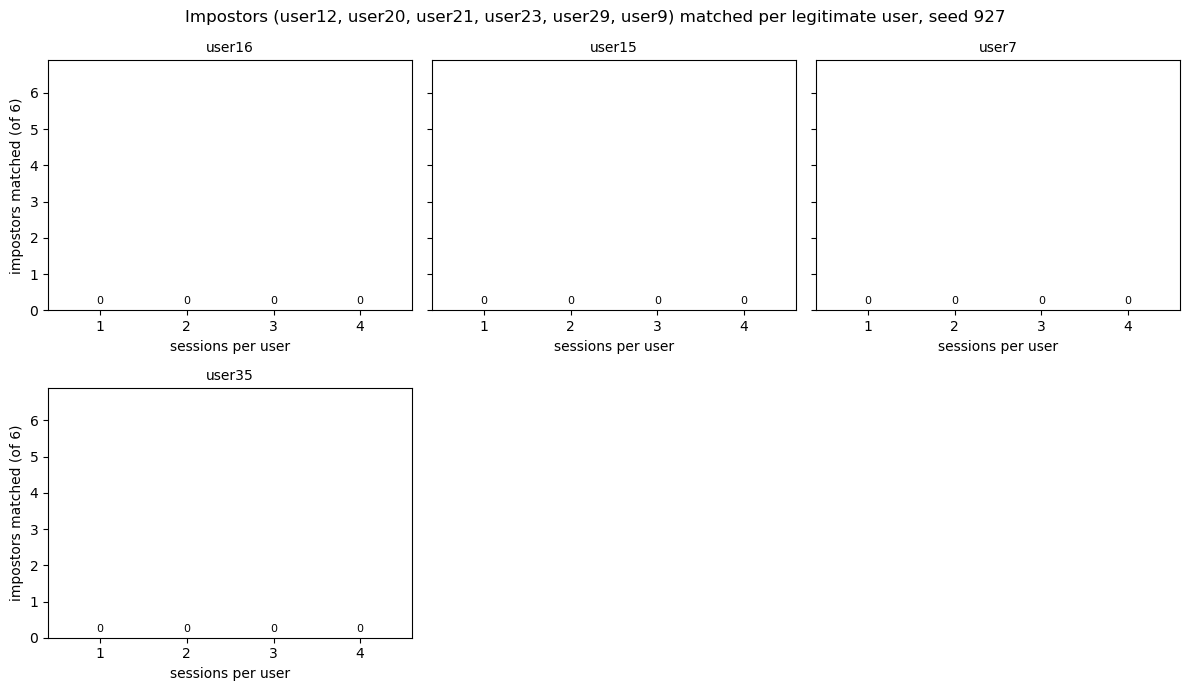

In [9]:
import textwrap

full = steps[steps["legit_users"] == N_LEGITIMATE]
per_user = pd.DataFrame([
    {"profile": p, "sessions": r.sessions, "impostor": r.impostor, "matched": p in r.matched_by.split(",")}
    for r in full.itertuples() for p in legit
])
per_user = per_user.groupby(["profile", "sessions"], sort=False)["matched"].sum().rename("impostors_matched").reset_index()
per_user.to_csv(RUN / "results" / "session_progression_users.csv", index=False)

n_cols = min(3, N_LEGITIMATE)
n_rows = -(-N_LEGITIMATE // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(bar_width(len(SESSION_STEPS), 4) * n_cols, 3.3 * n_rows + 0.4),
                         sharey=True, squeeze=False)
for ax, profile in zip(axes.flat, legit):
    values = per_user[per_user["profile"] == profile].set_index("sessions")["impostors_matched"].reindex(SESSION_STEPS, fill_value=0).to_numpy()
    colours = ["tab:red" if v == values.max() and v > 0 else "tab:blue" for v in values]
    bars = ax.bar(SESSION_STEPS, values, color=colours)
    ax.bar_label(bars, labels=bar_labels(values), padding=3, fontsize=8)
    step_axis(ax, SESSION_STEPS)
    ax.set_title(profile, fontsize=10)
    ax.set_xlabel("sessions per user")
for ax in axes[:, 0]:
    ax.set_ylabel(f"impostors matched (of {N_IMPOSTOR})")
for ax in axes.flat[N_LEGITIMATE:]:
    ax.set_visible(False)
axes[0, 0].set_ylim(0, N_IMPOSTOR * 1.15)
axes[0, 0].set_yticks(range(N_IMPOSTOR + 1))
title = f"Impostors ({', '.join(impostor)}) matched per legitimate user, seed {SEED}"
fig.suptitle(textwrap.fill(title, width=int(11 * fig.get_figwidth())))  # wrap long impostor lists
fig.tight_layout()
fig.savefig(RUN / "figures" / "session_progression_users.png", dpi=150)
plt.show()

## 7. Heatmap: sessions per user x legitimate users

Cell colour = sensitivity (formerly threshold: impostors matched / `n_impostor`), fixed 0.0 to 1.0 scale in steps of 0.1, 0 = best.
The second line in each cell is the same result as the number of impostors matched.

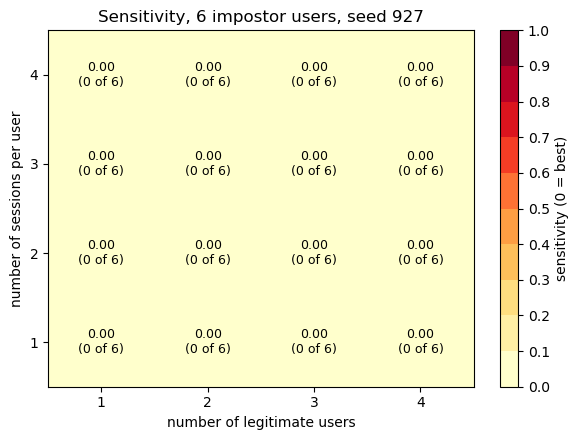

In [10]:
from matplotlib.colors import BoundaryNorm

levels = np.round(np.arange(0, 1.01, 0.1), 1)
fig, ax = plt.subplots(figsize=(6, 4.5))
image = ax.imshow(heatmap.to_numpy(), cmap="YlOrRd", norm=BoundaryNorm(levels, 256), origin="lower", aspect="auto")
ax.set_xticks(range(len(heatmap.columns)), heatmap.columns)
stride = -(-len(heatmap.index) // MAX_LABELLED)  # 1 for a short run: every row labelled
rows = list(range(0, len(heatmap.index), stride))
ax.set_yticks(rows, heatmap.index[rows])
if len(heatmap.index) <= MAX_LABELLED:  # long runs: values only in session_progression_heatmap.csv
    for r, k in enumerate(heatmap.index):
        for c, n_legit in enumerate(heatmap.columns):
            ax.text(c, r, f"{heatmap.loc[k, n_legit]:.2f}\n({heatmap_matched.loc[k, n_legit]:.0f} of {N_IMPOSTOR})",
                    ha="center", va="center", fontsize=9)
ax.set_xlabel("number of legitimate users")
ax.set_ylabel("number of sessions per user")
ax.set_title(f"Sensitivity, {N_IMPOSTOR} impostor users, seed {SEED}")
fig.colorbar(image, ax=ax, ticks=levels, label="sensitivity (0 = best)")
fig.tight_layout()
fig.savefig(RUN / "figures" / "session_progression_heatmap.png", dpi=150)
plt.show()

## Notes

- The tolerance in `config.yaml` (0.02) is the value that keeps the metric from being all 0 or all 1. In the earlier sweep a user's own held-out sessions never matched
  more than impostors did, so read these numbers as a baseline for how the sensitivity grows with more sessions, not as proof that shapes are unique to a user.
- Balabit has 10 users, so `n_legitimate + n_impostor` can be at most 10, and `sessions_per_user` at most 114 (the smallest session count of any user); the notebook stops with a message otherwise.
- Settings come from `config.yaml`; a new config creates a new `runs/` folder, so older results are kept.
- The `src/` scripts remain the reference for the file-based flow (`temp/`, `shapes/`, `results/trial_k.json`).